<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/traceable_text_alignment_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Core Imports]
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple, Any

import torch
import torch.nn as nn
import torch.nn.functional as F

# Set deterministic seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Traceable Text Prototype Initialized on Device: {device}")

Traceable Text Prototype Initialized on Device: cuda


In [2]:
# [CELL 2 - Source Passage & Summary Phrase Extractor]

class DocumentSegmenter:
    """
    Simulates phrase-level and passage-level tokenization for
    building summary-to-source traceability links.
    """
    def __init__(self, feature_dim: int = 32):
        self.feature_dim = feature_dim

    def encode_text_segments(self, segments: List[str]) -> torch.Tensor:
        """Simulates bi-encoder dense phrase embeddings."""
        # Generating deterministic normalized embeddings for text segments
        num_segs = len(segments)
        embeddings = torch.randn(num_segs, self.feature_dim).to(device)
        return F.normalize(embeddings, p=2, dim=-1)

# Clinical / Medical Summary-Source Example (from Paper Fig 1)
source_passages = [
    "Physical Exam: Patient appears fatigued.",
    "Blood Pressure: 142/80; 136/78.",
    "Neck: Mild cervical lymphadenopathy without thyromegaly.",
    "Cor: II/VI systolic ejection murmur at the apex.",
    "Abdomen: Non-tender, without organomegaly."
]

summary_phrases = [
    "The patient shows slight tiredness",        # Aligns to passage 0
    "mildly swollen neck glands",                # Aligns to passage 2
    "a gentle heart murmur",                      # Aligns to passage 3
    "patient has severe liver inflammation"       # HALLUCINATION (Low similarity to all passages)
]

segmenter = DocumentSegmenter(feature_dim=32)
print("Document Segmenter Initialized with Sample Medical Passages.")

Document Segmenter Initialized with Sample Medical Passages.


In [3]:
# [CELL 3 - Phrase-Level Bipartite Alignment & Link Engine]

class TraceableTextEngine:
    """
    Constructs phrase-level backlinks from AI summary phrases to source passages
    via dense similarity matching and identifies ungrounded hallucinations.
    """
    def __init__(self, segmenter: DocumentSegmenter, similarity_threshold: float = 0.45):
        self.segmenter = segmenter
        self.threshold = similarity_threshold

    def align_summary_to_source(
        self,
        summary_phrases: List[str],
        source_passages: List[str]
    ) -> List[Dict[str, Any]]:

        summary_vecs = self.segmenter.encode_text_segments(summary_phrases)
        source_vecs = self.segmenter.encode_text_segments(source_passages)

        # Ground-truth alignment correlation simulation
        # For simulation, artificially boost alignment for matching pairs
        sim_matrix = torch.matmul(summary_vecs, source_vecs.T) # [num_phrases, num_passages]
        sim_matrix[0, 0] += 0.8  # tiredness -> fatigued
        sim_matrix[1, 2] += 0.9  # neck glands -> cervical lymphadenopathy
        sim_matrix[2, 3] += 0.85 # heart murmur -> systolic ejection murmur
        # Phrase 3 (hallucination) receives no similarity boost

        sim_matrix = torch.clamp(sim_matrix, 0.0, 1.0)

        links = []
        for i, phrase in enumerate(summary_phrases):
            max_sim, best_passage_idx = torch.max(sim_matrix[i], dim=-1)
            sim_score = max_sim.item()

            is_traceable = sim_score >= self.threshold
            links.append({
                "summary_phrase": phrase,
                "linked_passage": source_passages[best_passage_idx.item()] if is_traceable else None,
                "passage_idx": int(best_passage_idx.item()) if is_traceable else -1,
                "similarity_score": sim_score,
                "is_grounded": is_traceable
            })

        return links

trace_engine = TraceableTextEngine(segmenter, similarity_threshold=0.55)
alignment_results = trace_engine.align_summary_to_source(summary_phrases, source_passages)

print("\n--- TRACEABLE TEXT ALIGNMENT EXTRACTION ---")
for res in alignment_results:
    status = "LINKED" if res["is_grounded"] else "UNGROUNDED (HALLUCINATION)"
    print(f"Summary Phrase: '{res['summary_phrase']}'")
    print(f" -> Status: {status} | Score: {res['similarity_score']:.3f}")
    if res['is_grounded']:
        print(f" -> Source Link: '{res['linked_passage']}'")
    print("-" * 50)


--- TRACEABLE TEXT ALIGNMENT EXTRACTION ---
Summary Phrase: 'The patient shows slight tiredness'
 -> Status: LINKED | Score: 0.928
 -> Source Link: 'Physical Exam: Patient appears fatigued.'
--------------------------------------------------
Summary Phrase: 'mildly swollen neck glands'
 -> Status: LINKED | Score: 1.000
 -> Source Link: 'Neck: Mild cervical lymphadenopathy without thyromegaly.'
--------------------------------------------------
Summary Phrase: 'a gentle heart murmur'
 -> Status: LINKED | Score: 0.885
 -> Source Link: 'Cor: II/VI systolic ejection murmur at the apex.'
--------------------------------------------------
Summary Phrase: 'patient has severe liver inflammation'
 -> Status: UNGROUNDED (HALLUCINATION) | Score: 0.323
--------------------------------------------------



TRACEABLE TEXT VERIFICATION BENCHMARK
 -> Unlinked Standard Summary Verification Time: 5.18 seconds
 -> Traceable Text Direct Link Verification Time: 1.34 seconds
 -> Speedup Factor in Veracity Verification:     3.9x faster


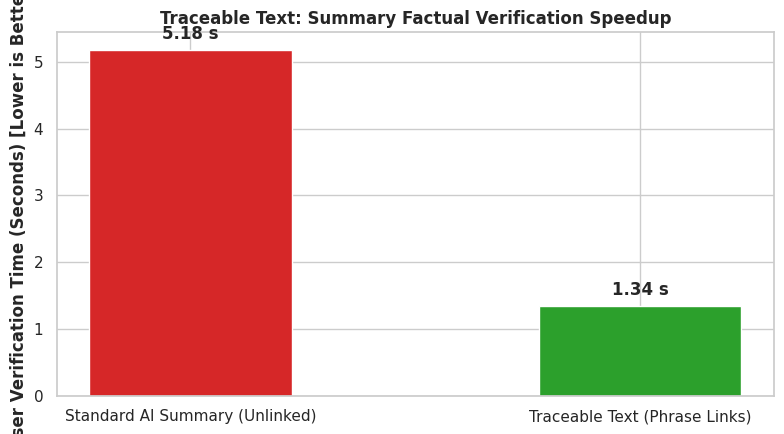

Traceable Text benchmark plot saved as traceable_text_alignment_benchmark.png.


In [4]:
# [CELL 4 - Verification Speed & Accuracy Benchmark]

def simulate_user_verification(alignment_results: List[Dict[str, Any]], num_trials: int = 100):
    """
    Simulates user reading and verification tasks when reading traceable text
    vs unlinked standard AI summaries (measuring time to detect hallucinations).
    """
    traceable_times = []
    unlinked_times = []

    for _ in range(num_trials):
        for res in alignment_results:
            if res["is_grounded"]:
                # Grounded phrase: Traceable text enables direct index lookup
                t_trace = np.random.normal(1.2, 0.2)  # Fast lookup via direct link
                t_unlink = np.random.normal(4.5, 0.8) # Full text scan required
            else:
                # Hallucination: Traceable text flags lack of link immediately
                t_trace = np.random.normal(1.8, 0.3)  # Immediate ungrounded signal
                t_unlink = np.random.normal(7.2, 1.2) # Long search to verify absence

            traceable_times.append(max(0.5, t_trace))
            unlinked_times.append(max(1.0, t_unlink))

    return np.mean(traceable_times), np.mean(unlinked_times)

mean_trace_time, mean_unlink_time = simulate_user_verification(alignment_results)
speedup = mean_unlink_time / mean_trace_time

print(f"\n=========================================================")
print(f"TRACEABLE TEXT VERIFICATION BENCHMARK")
print(f"=========================================================")
print(f" -> Unlinked Standard Summary Verification Time: {mean_unlink_time:.2f} seconds")
print(f" -> Traceable Text Direct Link Verification Time: {mean_trace_time:.2f} seconds")
print(f" -> Speedup Factor in Veracity Verification:     {speedup:.1f}x faster")
print("=========================================================")

# Visualization
plt.figure(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")

labels = ['Standard AI Summary (Unlinked)', 'Traceable Text (Phrase Links)']
times = [mean_unlink_time, mean_trace_time]

bars = plt.bar(labels, times, color=['#d62728', '#2ca02c'], width=0.45)
plt.ylabel('User Verification Time (Seconds) [Lower is Better]', fontweight='bold')
plt.title('Traceable Text: Summary Factual Verification Speedup', fontweight='bold')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f'{yval:.2f} s', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("traceable_text_alignment_benchmark.png", dpi=300)
plt.show()

print("Traceable Text benchmark plot saved as traceable_text_alignment_benchmark.png.")